# A demo for applying the method to tree sequences inferred by Wohns et. al. (2021)

In [38]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import tskit
import sys
import os
sys.path.append("../src/")
import seaborn as sns
import matplotlib.pyplot as plt
from pathos.multiprocessing import ProcessingPool as Pool

from CountCoalEvents import CountCoalEvents
from LatentSpaceEmbeddings import LatentSpaceEmbeddings
from PlotEmbeddings import PlotEmbeddings
import plotly.io as pio

def parse_counts_df(counts_df, delta):
    num_idx = counts_df["sample_2_idx"].max()+1
    num_time_points = counts_df["time_idx"].nunique()
    N = np.zeros((num_idx, num_idx, num_time_points), dtype=float)
    L = np.zeros((num_idx, num_idx, num_time_points), dtype=float)
    for row in counts_df.itertuples():
        # R[row.sample_1_idx, row.sample_2_idx, row.time_idx] = row.coal_rate
        N[row.sample_1_idx, row.sample_2_idx, row.time_idx] = row.num_coal_events
        L[row.sample_1_idx, row.sample_2_idx, row.time_idx] = row.num_uncoalesced
    
    # R += R.transpose((1,0,2))
    N += N.transpose((1,0,2))
    L += L.transpose((1,0,2))
    # R = (N+1)/(delta*(L+1))
    R = N/(delta*L)
    return N,L,R


## Coalescent Counts

### Printing all population labels in Wohns dataset
Pick out from these IDs to choose particular subpopulations for analysis

In [39]:
ts_dir = "../data/trees/wohns/"
population_labels = pd.read_csv("../data/trees/wohns/metadata.csv")
populations = population_labels["population"].unique()
population_descriptions = {row[1].population: row[1].description for row in population_labels[["population", "description"]].drop_duplicates().reset_index(drop=True).iterrows()}
counts = population_labels.groupby("population")["sample_id"].nunique().sort_values(ascending=False)
print("population_id (population description): num_samples")
for pop, cnt in counts.items():
    print(f"{pop}({population_descriptions[pop]}): {cnt}")

population_id (population description): num_samples
GWD(Gambian in Western Divisions in the Gambia): 226
TSI(Toscani in Italia): 222
IBS(Iberian Population in Spain): 214
YRI(Yoruba in Ibadan, Nigeria): 214
CHB(Han Chinese in Beijing, China): 212
GIH(Gujarati Indian from Houston, Texas): 212
JPT(Japanese in Tokyo, Japan): 210
FIN(Finnish in Finland): 210
CHS(Southern Han Chinese): 210
PUR(Puerto Ricans from Puerto Rico): 208
LWK(Luhya in Webuye, Kenya): 206
STU(Sri Lankan Tamil from the UK): 204
ITU(Indian Telugu from the UK): 204
CDX(Chinese Dai in Xishuangbanna, China): 200
GBR(British in England and Scotland): 200
ESN(Esan in Nigeria): 200
KHV(Kinh in Ho Chi Minh City, Vietnam): 198
CEU(Utah Residents (CEPH) with Northern and Western Eu): 198
ACB(African Caribbeans in Barbados): 194
PJL(Punjabi from Lahore, Pakistan): 192
CLM(Colombians from Medellin, Colombia): 190
MSL(Mende in Sierra Leone): 180
BEB(Bengali from Bangladesh): 172
PEL(Peruvians from Lima, Peru): 170
MXL(Mexican Ance

### Computing counts for samples from a set of populations

### Choosing certain populations

In [41]:
chosen_populations = ["YRI","CEU"] # Adjust as needed
sample_ids = population_labels[population_labels["population"].isin(chosen_populations)]["sample_id"].values
population_sample_dict = {pop: population_labels[population_labels["population"] == pop]["sample_id"].values for pop in chosen_populations}
output_dir_name = "_".join([pop[:3] for pop in chosen_populations])
output_dir = f"../tests/wohns/{output_dir_name}"
assert not os.path.exists(output_dir), f"Output directory {output_dir} already exists. Please choose a different set of populations or delete the existing directory."    

## All populations
# chosen_populations = population_labels[population_labels.region != "Ancient"].population.values
# population_sample_dict = {}
# for pop in chosen_populations:
#     pop_samples = population_labels[population_labels["population"] == pop]["sample_id"].values
#     random_sample = 2*(np.random.choice(pop_samples, size=1, replace=False)//2)[0]
#     population_sample_dict[pop] = np.array([random_sample,random_sample+1])
# sample_ids = [sample for pop_samples in population_sample_dict.values() for sample in pop_samples]

# Adjust dir names accordingly
# output_dir = "../tests/wohns/OOA4"
# output_dir_name = "all_wohns"


### Counting coalescent events for the chosen samples

In [42]:
time_points = np.logspace(1, np.log10(8000), 100, base=10) # Adjust as needed
window_sizes = np.array([100]*len(time_points)) # Adjust as needed

CoalCounter = CountCoalEvents(
    output_dir = output_dir,
    ts_dir = ts_dir,
    time_points = time_points,
    window_sizes = window_sizes,
    sample_ids = sample_ids,
    num_posterior_samples = None,
    thinning_fraction = 0.5 # I'm still testing this parameter, and might change the way I perform thinning all together later on
)
CoalCounter.count_coal_events_total(num_threads=os.cpu_count())
aggregated_counts = CoalCounter.aggregate_counts()
N,L,R = parse_counts_df(aggregated_counts, delta = window_sizes[0])


/var/folders/r7/bmbjyrls5rg24ycmhm0lgjd40000gp/T/ipykernel_2210/268331462.py:31: RuntimeWarning:

invalid value encountered in divide



### Visualizing heatmaps of coal counts, num uncoalesced loci, and pairwise coal rates for a chosen time point

Plotting results for time point: 8000.00 generations ago = 240000.000000 years ago (assuming 30 years/generation)


Text(0.5, 1.0, 'Coalescent Rate Estimate')

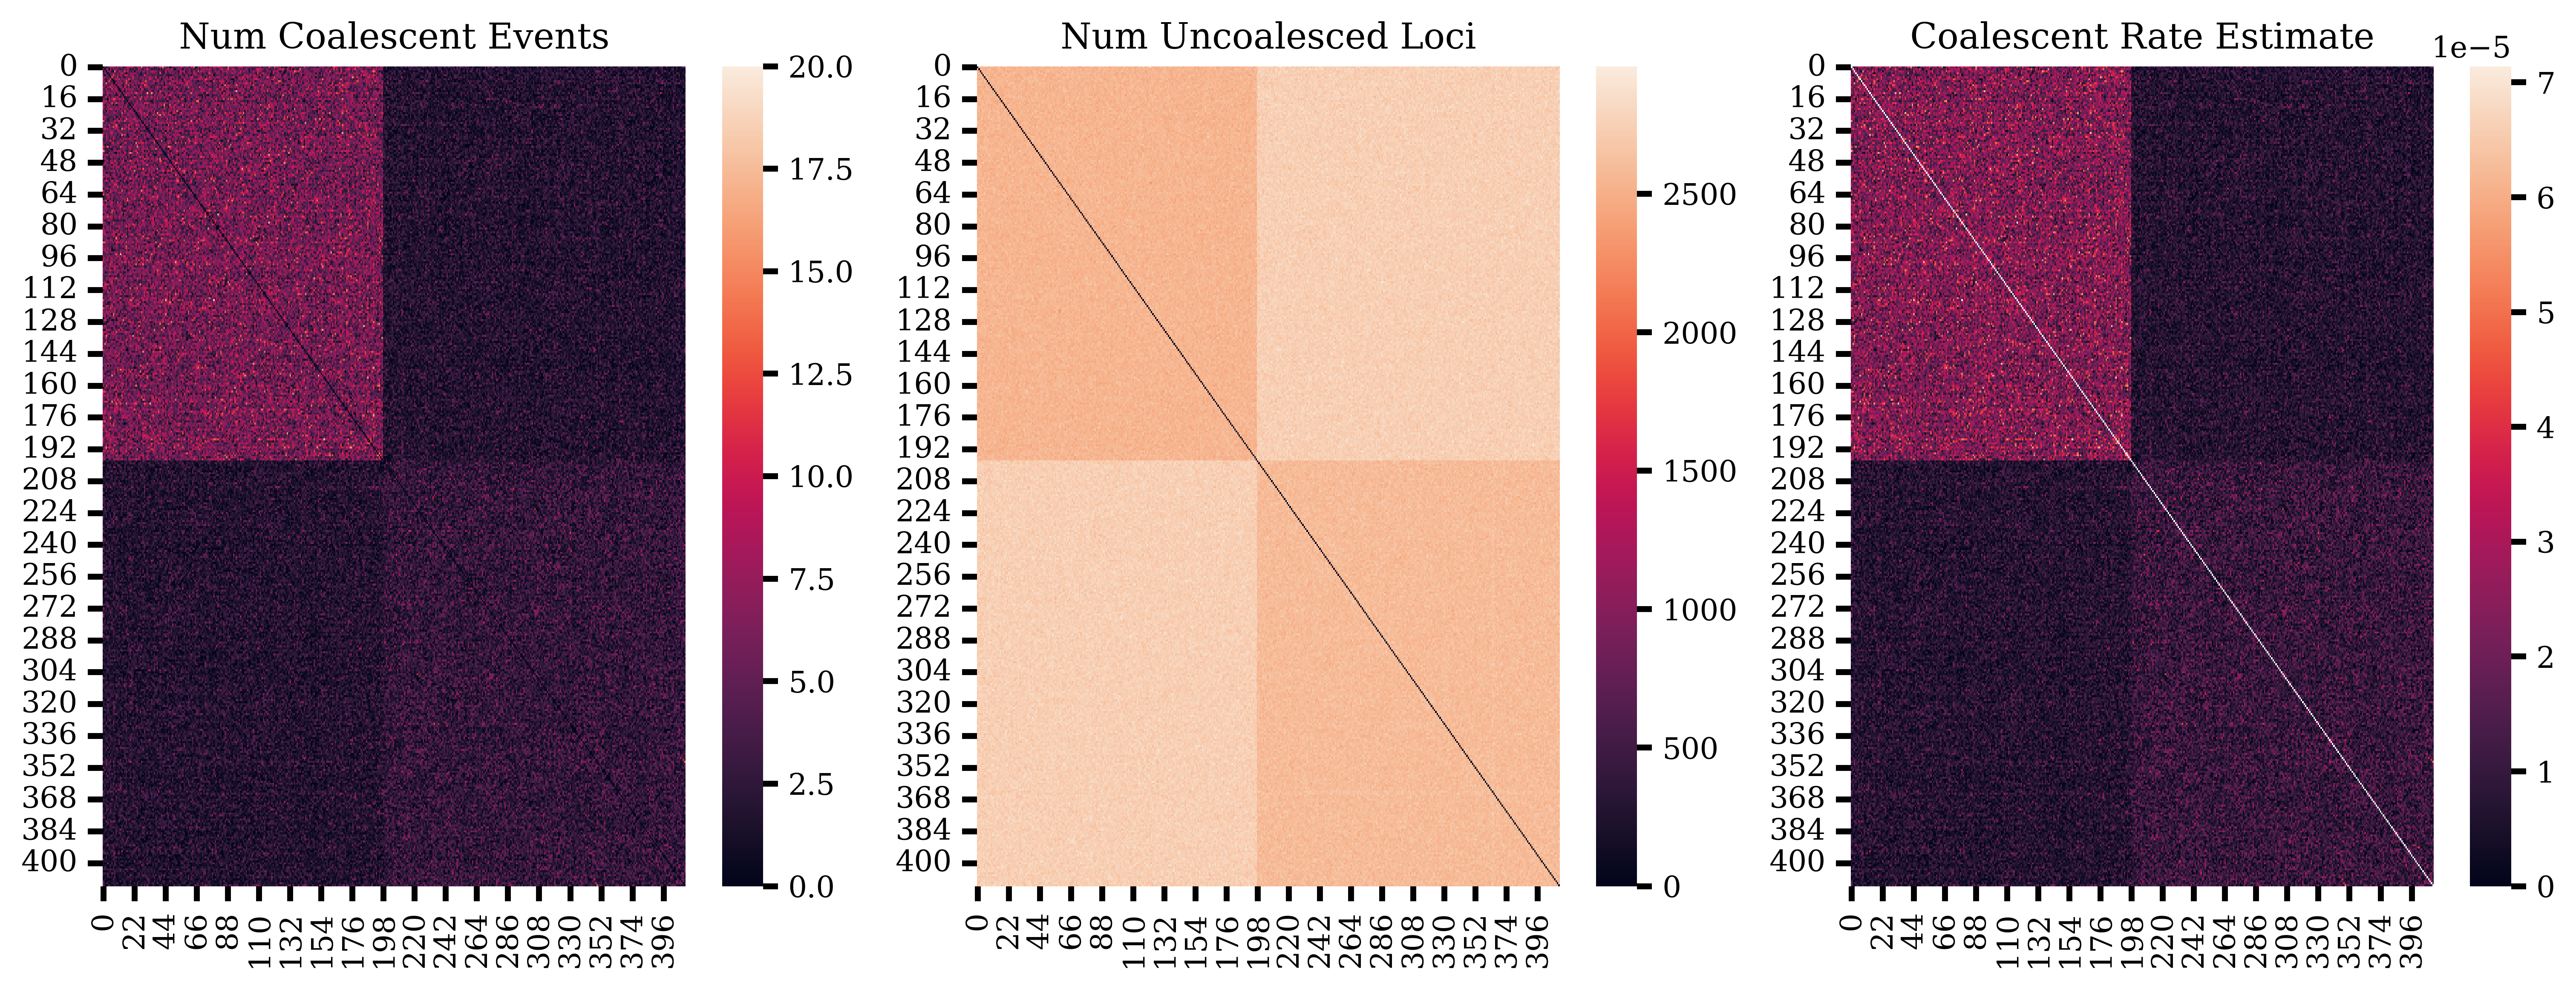

In [51]:
time_idx = 99
print(f"Plotting results for time point: {time_points[time_idx]:.2f} generations ago = {time_points[time_idx]*30:0f} years ago (assuming 30 years/generation)")
fig, axes = plt.subplots(1,3,figsize=(15,5),dpi=500)
sns.heatmap(N[:,:,time_idx], ax=axes[0],vmin = 0, vmax=20)
sns.heatmap(L[:,:,time_idx], ax=axes[1])
sns.heatmap(R[:,:,time_idx], ax=axes[2],vmin=0)#,vmax=1e-5)
axes[0].set_title("Num Coalescent Events")
axes[1].set_title("Num Uncoalesced Loci")
axes[2].set_title("Coalescent Rate Estimate")

## Latent Embeddings

### Compute Embeddings

In [44]:
# time_points = np.logspace(1, np.log10(20000), 200, base=10)
# window_sizes = np.array([100]*len(time_points))

# output_dir = "../tests/wohns/OOA4"
total_counts_df = pd.read_parquet(os.path.join(output_dir, "total_counts.parquet"))

N,L,R = parse_counts_df(total_counts_df, delta = window_sizes[0])
LSE = LatentSpaceEmbeddings(R=R, time_points=time_points)

embeddings = LSE.compute_embeddings_through_time(X_init=np.random.rand(R.shape[0], 2))
embeddings_df = LSE.create_embeddings_df()
embeddings_df.to_parquet(os.path.join(output_dir, "embeddings.parquet"), index=False)

/var/folders/r7/bmbjyrls5rg24ycmhm0lgjd40000gp/T/ipykernel_2210/268331462.py:31: RuntimeWarning:

invalid value encountered in divide

100%|██████████| 100/100 [00:41<00:00,  2.40it/s]


### Plot Embeddings

In [45]:
# sample_colors = {}
# pop_colors = pd.read_csv("../data/trees/wohns/population_colors.csv")
# for i,sample_id in enumerate(sample_ids):
#     population = population_labels[population_labels["sample_id"] == sample_id]["population"].values[0]
#     color = pop_colors[pop_colors["population"] == population]["hex_colour"].values[0]
#     sample_colors[i] = color
# embeddings_df['color'] = embeddings_df['idx'].map(sample_colors)

In [46]:
idx_to_sample_df = pd.read_parquet(os.path.join(output_dir, "idx_to_sample.parquet"))
sample_to_pop_df = pd.read_csv("../data/trees/wohns/metadata.csv")[["sample_id","population"]]
plotter = PlotEmbeddings(embeddings_df=embeddings_df, sample_to_pop_df=sample_to_pop_df, idx_to_sample_df=idx_to_sample_df)
fig = plotter.dynamic_plot(log_time=True)
pio.write_html(fig, file=os.path.join(output_dir, "dynamic_3d_plot.html"))
fig.show()

### Plot embeddings for a particular time point

Text(0.5, 1.0, 'Latent Space Embeddings at 2.4e+05 years ago')

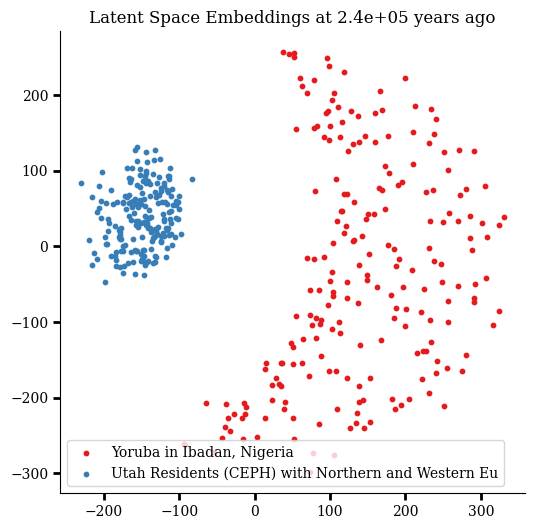

In [50]:
time_idx = 99
X,loss = LSE.compute_embeddings(time_inx = time_idx,X_init=np.random.rand(R.shape[0], 2))
cmap = plt.get_cmap("Set1")
colors = cmap(np.arange(len(chosen_populations)))[:,:-1]
for i,population in enumerate(chosen_populations):
    pop_indices = population_sample_dict[population]
    pop_mask = idx_to_sample_df['sample_id'].isin(pop_indices)
    plt.scatter(X[pop_mask,0], X[pop_mask,1], label=population_descriptions[population], s=10, color = colors[i])
plt.legend()
plt.title(f"Latent Space Embeddings at {time_points[time_idx]*30:.1e} years ago")